# Baselines for the Binary Version (rating == 5) on Cold-Start Recipes

**This is the supplementary binary version of the task.** The main task, predicting the 1–5 rating and evaluating with MSE, is in `03_baselines_rating.ipynb`; both notebooks use the same training rows, features, and evaluation protocol. Here the target is whether the user gives a recipe with no training reviews **5 stars**, and the score is in [0, 1].

| | Baseline | Information used |
|---|---|---|
| B0 | constant | none |
| B1 | ID-only logistic bias model, $\sigma(\alpha + \beta_u + \beta_i)$ | user and recipe ids |
| B2 | logistic regression on user-history features | the user's past ratings |
| B3 | TF-IDF cosine (content-only): similarity of the recipe text to the user's past recipes | recipe text + which past recipes the user loved |
| B4 | BPR, $\beta_i + \gamma_u \cdot \gamma_i$, trained on implicit feedback (who reviewed what) | user and recipe ids |

Hyperparameters are chosen on the **validation** cold rows (2013). In Section 6 every baseline is refit on train + validation and evaluated once on the **test** split (2014–2018) with AUC, Hit@10 and NDCG@10.

The feature code lives in `features.py` and the evaluation code in `evaluate.py`, so the main models reuse exactly the same pipeline.

In [1]:
import sys
sys.path.append("..")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import sparse
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

import features as F
import evaluate as E

import plots as P

P.setup()
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

In [2]:
splits, recipes = F.load_data()
train, valid, test = splits["train"], splits["validation"], splits["test"]

# content representations use recipe content only (no ratings), so they can be built from all recipes
content = F.content_matrix(recipes, F.top_vocab(recipes.tags, F.N_TAGS), F.top_vocab(recipes.ingredients, F.N_INGREDIENTS))
X_text = F.tfidf_matrix(recipes)
print(f"TF-IDF over name + tags + ingredients + description + steps: {X_text.shape[0]:,} recipes x {X_text.shape[1]:,} terms")

TF-IDF over name + tags + ingredients + description + steps: 178,265 recipes x 20,425 terms


## 1. Pseudo-cold training set

The training split contains no cold-start rows: every recipe in it has reviews. To train models under the same conditions as the evaluation, we use the reviews written **on the first day a recipe was reviewed**. At that moment the recipe had no reviews, exactly like a cold validation/test row.

Two filters make the training rows match the evaluation rows:
- **at least 3 earlier ratings by the user** (every validation/test user has at least 3 training ratings);
- **sample weight $1/\sqrt{n_u}$**, where $n_u$ is the user's number of training rows, so a few heavy users do not dominate.

In [3]:
def training_set(history):
    rows = F.pseudo_cold_rows(history)
    feats = F.build_features(rows, history, recipes, content, tfidf=X_text)
    keep = (feats.u_n >= F.MIN_PRIOR).values
    return rows[keep], feats[keep], F.training_weights(rows.user_id.values[keep]), len(rows)

train_rows, train_feats, train_w, n_all = training_set(train)
print(f"first-day reviews: {n_all:,}; with >= {F.MIN_PRIOR} earlier user ratings: {len(train_rows):,} ({len(train_rows) / n_all:.1%})")
print(f"share rating == 5: {train_rows.y.mean():.1%} (weighted {np.average(train_rows.y, weights=train_w):.1%})")

first-day reviews: 169,023; with >= 3 earlier user ratings: 151,945 (89.9%)
share rating == 5: 72.5% (weighted 70.6%)


## 2. Time-aware features

Every history feature of a row (user, recipe, date) is computed from reviews dated **strictly before** that date. The same function serves all cases; only the `history` table changes:

| rows | history passed in |
|---|---|
| pseudo-cold training rows | train (each row sees only its own past) |
| validation rows | train |
| test rows (Section 6) | train + validation |

The baselines use two groups:

| Group | Features |
|---|---|
| B. user | `u_n` (# past ratings), `u_rate` (5-star share), `u_rate_smooth` (shrunk towards the global share with 10 pseudo-ratings), `u_mean`, `u_std` |
| T. text | cosine between the recipe's TF-IDF vector and the centroid of the user's past recipes: all of them (`t_cos_all`) and the 5-star ones (`t_cos_liked`) |

The remaining groups (recipe content, user × recipe match, author) are built by the same function and used by the main models.

In [4]:
valid_feats = F.build_features(valid, train, recipes, content, tfidf=X_text)
cold = (valid.cold == 1).values
y_valid = (valid.rating == 5).astype(int).values
users_valid = valid.user_id.values
print(f"validation rows: {len(valid):,} ({cold.sum()} cold, {(~cold).sum():,} warm)")

validation rows: 22,933 (6410 cold, 16,523 warm)


### Correctness check

We recompute a sample of features the slow, obvious way (filter the user's reviews before the date, then compute) and compare with the vectorized version.

In [5]:
pos = pd.Series(np.arange(len(recipes)), index=recipes.index)
rng = np.random.default_rng(0)
mismatches = 0
for i in rng.choice(len(train_rows), 200, replace=False):
    row, f = train_rows.iloc[i], train_feats.iloc[i]
    past = train[(train.user_id == row.user_id) & (train.date < row.date)]
    assert past.date.max() < row.date and f.u_n == len(past)
    liked = past[past.rating == 5]
    centroid = np.asarray(X_text[pos[liked.recipe_id].values].sum(0)).ravel()
    target = X_text[pos[row.recipe_id]].toarray().ravel()
    denom = np.linalg.norm(centroid) * np.linalg.norm(target)
    cos_liked = centroid @ target / denom if denom > 0 else np.nan
    checks = [(f.u_rate, (past.rating == 5).mean()), (f.t_cos_liked, cos_liked)]
    mismatches += sum(not np.isclose(a, b, equal_nan=True, atol=1e-4) for a, b in checks)
print(f"checked 200 rows: {mismatches} mismatches")

checked 200 rows: 0 mismatches


### Do the training rows look like the evaluation rows?

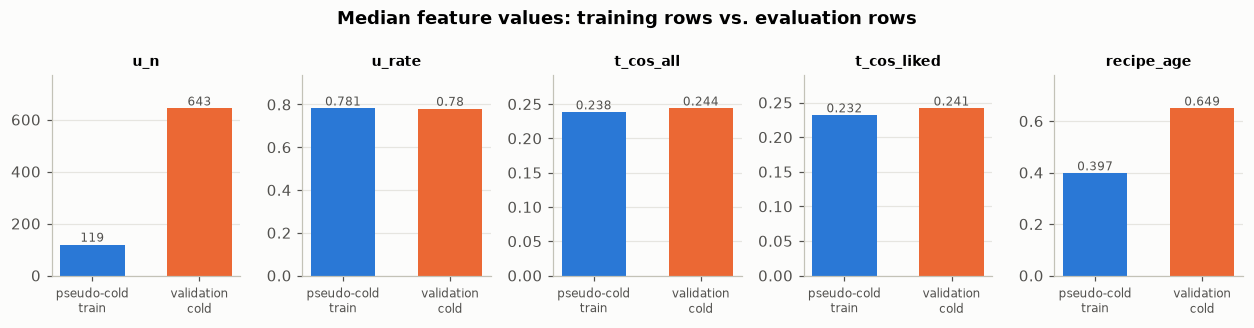

In [6]:
cols = ["u_n", "u_rate", "t_cos_all", "t_cos_liked", "recipe_age"]
P.compare_medians(train_feats[cols].median(), valid_feats.loc[cold, cols].median(),
                  ["pseudo-cold\ntrain", "validation\ncold"], "Median feature values: training rows vs. evaluation rows")

Most features line up. Validation users have much longer histories (they had to be active before 2013), and validation cold rows are for somewhat older recipes (median recipe age 0.65 vs. 0.40 years), because pseudo-cold training rows are first reviews, which usually arrive soon after a recipe is posted. The ablation of the main models checks whether `recipe_age` causes extrapolation problems.

## 3. Evaluation protocol

- **Rows**: validation rows with `cold == 1` (6,410 rows, 859 users). Warm rows are reported only as a comparison.
- **Metric**: AUC (threshold-free and insensitive to the ~80% positive rate), plus log loss for scores that are probabilities.
- **Uncertainty**: 95% confidence intervals from 1,000 bootstrap samples that **resample users** (a few users contribute many rows). Model comparisons use a paired bootstrap on the same samples.

In [7]:
results, scores = {}, {}
def report(name, score, is_prob=True):
    scores[name] = np.asarray(score, dtype=float)
    results[name] = r = E.evaluate(y_valid[cold], scores[name][cold], users_valid[cold], is_prob=is_prob)
    print(f"{name}: validation cold AUC {r['AUC']:.3f} (95% CI {r['CI low']:.3f}-{r['CI high']:.3f})")

## 4. Baselines

### B0: constant

Every row gets the (weighted) training share of 5-star ratings. Its AUC is 0.5 by definition; its log loss is the reference for calibration.

In [8]:
def fit_b0(rows, w):
    p = np.average(rows.y, weights=w)
    return lambda df, feats=None: np.full(len(df), p)

b0 = fit_b0(train_rows, train_w)
report("B0 constant", b0(valid))

B0 constant: validation cold AUC 0.500 (95% CI 0.500-0.500)


### B1: ID-only logistic bias model

The classic latent-factor baseline from the course, trained on **all** training ratings with a logistic loss:

$$P(y = 1 \mid u, i) = \sigma(\alpha + \beta_u + \beta_i)$$

This is a logistic regression on one-hot user and recipe indicators with L2 regularization. A cold recipe never appears in training, so it has no $\beta_i$ and its score collapses to $\sigma(\alpha + \beta_u)$: every cold recipe gets the same score for a given user. (Adding latent factors $\gamma_u \cdot \gamma_i$ does not help either, because an unseen recipe's $\gamma_i$ is never learned; B4 shows this for BPR.)

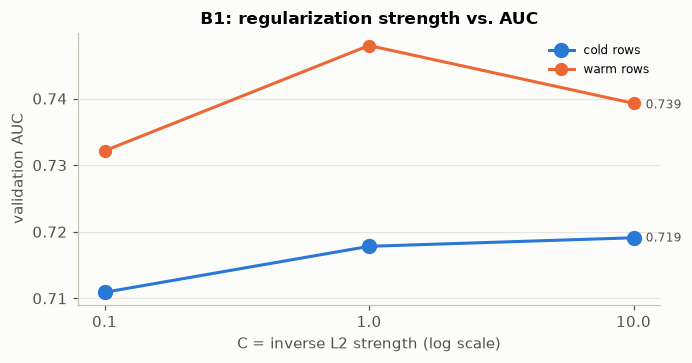

In [9]:
def one_hot(ids, index):
    col = pd.Series(ids).map(index)
    known = col.notna().values
    return sparse.csr_matrix((np.ones(known.sum()), (np.where(known)[0], col[known].astype(int))),
                             shape=(len(ids), len(index)))

def fit_b1(history, C):
    users = {u: j for j, u in enumerate(history.user_id.unique())}
    items = {r: j for j, r in enumerate(history.recipe_id.unique())}
    matrix = lambda df: sparse.hstack([one_hot(df.user_id.values, users), one_hot(df.recipe_id.values, items)]).tocsr()
    model = LogisticRegression(C=C, max_iter=500).fit(matrix(history), (history.rating == 5).astype(int))
    predict = lambda df, feats=None: model.predict_proba(matrix(df))[:, 1]
    predict.user_bias = pd.Series(model.coef_[0][:len(users)], index=list(users))
    return predict

b1_grid = []
for C in [0.1, 1.0, 10.0]:
    predict = fit_b1(train, C)
    p = predict(valid)
    b1_grid.append({"C": C, "cold AUC": E.evaluate(y_valid[cold], p[cold], users_valid[cold], n_boot=1)["AUC"],
                    "warm AUC": E.evaluate(y_valid[~cold], p[~cold], users_valid[~cold], n_boot=1)["AUC"],
                    "predict": predict, "p": p})
fig, ax = plt.subplots(figsize=(6.5, 3.4))
P.lines(ax, [r["C"] for r in b1_grid],
        {"cold rows": [r["cold AUC"] for r in b1_grid], "warm rows": [r["warm AUC"] for r in b1_grid]},
        "C = inverse L2 strength (log scale)", "validation AUC", title="B1: regularization strength vs. AUC", xlog=True)
plt.tight_layout(); plt.show()

In [10]:
best_b1 = max(b1_grid, key=lambda r: r["cold AUC"])
same = pd.Series(best_b1["p"][cold]).corr(
    pd.Series(best_b1["predict"].user_bias.reindex(valid.user_id[cold]).values), method="spearman")
print(f"C = {best_b1['C']}: rank correlation between cold-row scores and the user bias beta_u = {same:.4f}")
report("B1 ID-only bias model", best_b1["p"])

C = 10.0: rank correlation between cold-row scores and the user bias beta_u = 1.0000


B1 ID-only bias model: validation cold AUC 0.719 (95% CI 0.684-0.754)


On cold rows the B1 score is a monotone function of $\beta_u$ alone (rank correlation 1): the model only ranks *users*, never recipes. Any AUC it reaches comes from some users liking more recipes than others.

### B2: user-history features

A logistic regression on the time-aware user features, trained on the pseudo-cold rows. Like B1 it uses only information about the user, but the features are computed as of each review date and the model is fit under cold-start conditions.

In [11]:
USER_COLS = ["u_n", "u_rate", "u_rate_smooth", "u_mean", "u_std"]
def user_matrix(feats):
    return feats[USER_COLS].assign(u_n=np.log1p(feats.u_n))

def fit_b2(rows, feats, w):
    model = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
    model.fit(user_matrix(feats), rows.y, logisticregression__sample_weight=w)
    return lambda df, feats: model.predict_proba(user_matrix(feats))[:, 1]

b2 = fit_b2(train_rows, train_feats, train_w)
report("B2 user features", b2(valid, valid_feats))

B2 user features: validation cold AUC 0.721 (95% CI 0.688-0.756)


### B3: TF-IDF cosine (content-only)

Each recipe is represented by the TF-IDF vector of its name, tags, ingredients, description and steps. For a row we compare the recipe with the TF-IDF centroid of the user's earlier recipes:

- `t_cos_all`: similarity to everything the user reviewed before;
- `t_cos_liked`: similarity to the recipes the user rated 5 stars.

Each similarity alone is a ranking score; B3 combines the two with a logistic regression fit on the pseudo-cold rows. It uses no rating statistics of the user (no mean, no 5-star share), only how close the recipe's text is to what the user has cooked and loved.

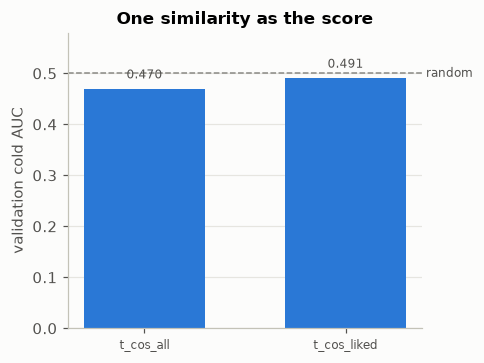

In [12]:
def text_matrix(feats):
    liked = feats.t_cos_liked.fillna(feats.t_cos_all)     # user without 5-star history: fall back to all recipes
    return pd.DataFrame({"t_cos_all": feats.t_cos_all.fillna(0), "t_cos_liked": liked.fillna(0)})

single = {c: E.evaluate(y_valid[cold], text_matrix(valid_feats)[c].values[cold], users_valid[cold], n_boot=1)["AUC"]
          for c in ["t_cos_all", "t_cos_liked"]}
fig, ax = plt.subplots(figsize=(4.5, 3.4))
P.bars(ax, list(single), list(single.values()), ref=0.5, title="One similarity as the score", ylabel="validation cold AUC")
plt.tight_layout(); plt.show()

In [13]:
def fit_b3(rows, feats, w):
    model = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
    model.fit(text_matrix(feats), rows.y, logisticregression__sample_weight=w)
    predict = lambda df, feats: model.predict_proba(text_matrix(feats))[:, 1]
    predict.coef = pd.Series(model[-1].coef_[0], index=["t_cos_all", "t_cos_liked"])
    return predict

b3 = fit_b3(train_rows, train_feats, train_w)
print("standardized coefficients:", b3.coef.round(3).to_dict())
report("B3 TF-IDF cosine", b3(valid, valid_feats))

standardized coefficients: {'t_cos_all': -1.0540000200271606, 't_cos_liked': 1.0850000381469727}


B3 TF-IDF cosine: validation cold AUC 0.618 (95% CI 0.595-0.640)


The coefficients have opposite signs: a recipe scores high when it is close to what the user **loved**, *relative to* what the user usually reviews.

### B4: BPR

Bayesian Personalized Ranking (from the course) learns from implicit feedback: for a user $u$, a reviewed recipe $i$ should score higher than a random recipe $j$:

$$\max \sum_{(u,i,j)} \ln \sigma(x_{ui} - x_{uj}) - \lambda \lVert\Theta\rVert^2, \qquad x_{ui} = \beta_i + \gamma_u \cdot \gamma_i$$

trained with minibatch SGD on all training reviews. A recipe that never appears in training keeps $\beta_i = 0$ and $\gamma_i = 0$, so **every cold recipe gets the same score**. To show that the model itself is working, we first check it on *warm* validation rows: each warm review is ranked against 99 random training recipes the user never reviewed.

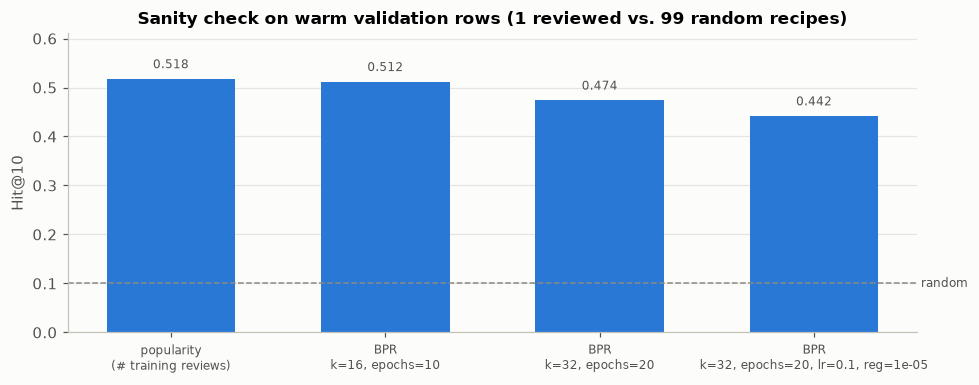

In [14]:
def fit_bpr(history, k=16, lr=0.05, reg=1e-4, epochs=10, batch=2048, seed=0):
    u = history.user_id.astype("category")
    i = history.recipe_id.astype("category")
    uc, ic = u.cat.codes.values, i.cat.codes.values
    rng = np.random.default_rng(seed)
    gu = 0.1 * rng.standard_normal((len(u.cat.categories), k))
    gi = 0.1 * rng.standard_normal((len(i.cat.categories), k))
    bi = np.zeros(len(i.cat.categories))
    for _ in range(epochs):
        for b in np.array_split(rng.permutation(len(uc)), len(uc) // batch):
            uu, ii, jj = uc[b], ic[b], rng.integers(len(bi), size=len(b))   # j: a random recipe
            x = bi[ii] - bi[jj] + (gu[uu] * (gi[ii] - gi[jj])).sum(1)
            g = 1 / (1 + np.exp(x))                                          # d ln sigma(x) / dx
            du = g[:, None] * (gi[ii] - gi[jj]) - reg * gu[uu]
            di, dj = g[:, None] * gu[uu] - reg * gi[ii], -g[:, None] * gu[uu] - reg * gi[jj]
            np.add.at(gu, uu, lr * du)
            np.add.at(gi, ii, lr * di)
            np.add.at(gi, jj, lr * dj)
            np.add.at(bi, ii, lr * (g - reg * bi[ii]))
            np.add.at(bi, jj, lr * (-g - reg * bi[jj]))
    user_ix = pd.Series(np.arange(len(gu)), index=u.cat.categories)
    item_ix = pd.Series(np.arange(len(bi)), index=i.cat.categories)

    def predict(df, feats=None):
        uj, ij = user_ix.reindex(df.user_id).values, item_ix.reindex(df.recipe_id).values
        s = np.zeros(len(df))                                                # unseen user or recipe: 0
        ok = ~np.isnan(uj) & ~np.isnan(ij)
        uj, ij = uj[ok].astype(int), ij[ok].astype(int)
        s[ok] = bi[ij] + (gu[uj] * gi[ij]).sum(1)
        return s
    return predict

reviewed = pd.concat([train, valid, test]).groupby("user_id").recipe_id.agg(set).to_dict()
warm_rows = valid[~cold].sample(1000, random_state=0)
warm_cands = E.sample_candidates(warm_rows, train.recipe_id.unique(), reviewed, recipes.submitted)
popularity = train.recipe_id.value_counts()

bpr_grid = [{"setting": "popularity (# training reviews)",
             "Hit@10": E.ranking_metrics(warm_cands, popularity.reindex(warm_cands.recipe_id).fillna(0).values)["Hit@10"].mean()}]
for params in [dict(k=16, epochs=10), dict(k=32, epochs=20), dict(k=32, epochs=20, lr=0.1, reg=1e-5)]:
    predict = fit_bpr(train, **params)
    bpr_grid.append({"setting": "BPR " + ", ".join(f"{k}={v}" for k, v in params.items()), "params": params, "predict": predict,
                     "Hit@10": E.ranking_metrics(warm_cands, predict(warm_cands))["Hit@10"].mean()})
fig, ax = plt.subplots(figsize=(9, 3.6))
P.bars(ax, [r["setting"] for r in bpr_grid], [r["Hit@10"] for r in bpr_grid], ref=0.1,
       title="Sanity check on warm validation rows (1 reviewed vs. 99 random recipes)", ylabel="Hit@10")
plt.tight_layout(); plt.show()

In [15]:
best_bpr = max([r for r in bpr_grid if "params" in r], key=lambda r: r["Hit@10"])
p = best_bpr["predict"](valid)
print(f"best BPR {best_bpr['params']}: distinct scores among cold rows = {len(np.unique(p[cold]))}")
report("B4 BPR", p, is_prob=False)   # BPR scores are not probabilities: no log loss

best BPR {'k': 16, 'epochs': 10}: distinct scores among cold rows = 1


B4 BPR: validation cold AUC 0.500 (95% CI 0.500-0.500)


BPR works on warm recipes (well above random), but on cold rows it outputs exactly 0 for every row: like B1, an ID-only model cannot say anything about a recipe it has never seen, and since BPR has no user-level term, it cannot even separate generous from strict users.

## 5. Validation results

In [16]:
table = pd.DataFrame(results).T

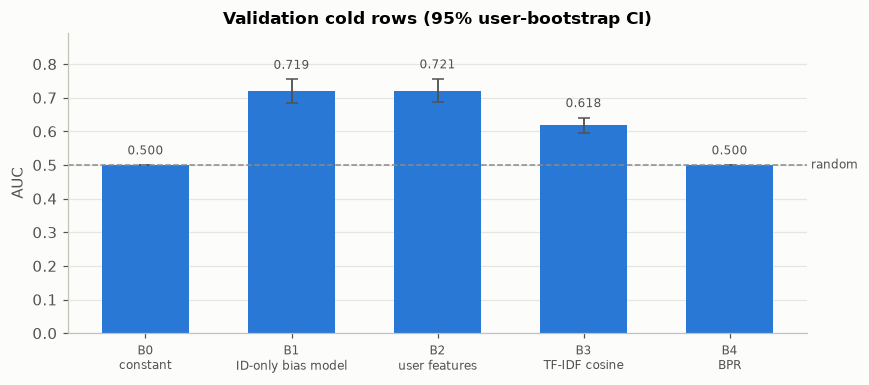

In [17]:
fig, ax = plt.subplots(figsize=(8, 3.6))
P.bars(ax, table.index, table["AUC"], table["CI low"], table["CI high"], ref=0.5,
       title="Validation cold rows (95% user-bootstrap CI)", ylabel="AUC")
plt.tight_layout(); plt.show()

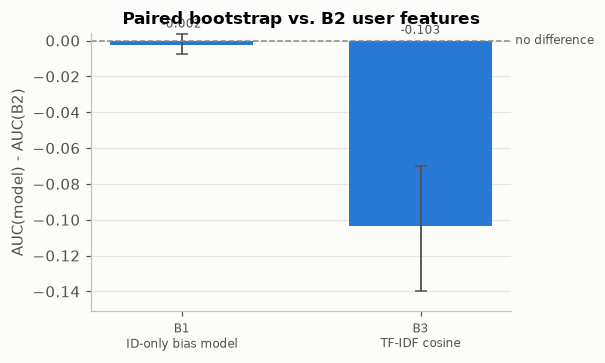

In [18]:
b2_name = "B2 user features"
diff = pd.DataFrame({name: E.compare(y_valid[cold], scores[name][cold], scores[b2_name][cold], users_valid[cold])
                     for name in ["B1 ID-only bias model", "B3 TF-IDF cosine"]}).T
P.diff_bars(diff, "AUC diff", f"Paired bootstrap vs. {b2_name}", "AUC(model) - AUC(B2)")

## 6. Test split: AUC, Hit@10 and NDCG@10

Every baseline is refit with the hyperparameters chosen above, now using **train + validation** as history (pseudo-cold training rows, user features, B1/B4 ids), and evaluated **once** on the test split (2014–2018).

- **AUC** on the 4,099 test cold rows: does the score separate 5-star reviews from the others, across all users?
- **Hit@10 / NDCG@10**: for each 5-star cold test review (3,263), the recipe is ranked against **99 cold recipes the user never reviewed** (no reviews in train + validation, already submitted at the review date). Hit@10 is 1 if the reviewed recipe lands in the top 10; NDCG@10 also rewards a higher position. Tied scores are broken at random, so a constant score gets Hit@10 = 0.10.

The two kinds of metrics ask different questions: AUC compares rows of *different* users, so knowing which users are generous already helps; Hit@10 and NDCG@10 rank recipes *for one user*, so only information about the recipe can help.

In [19]:
full = pd.concat([train, valid], ignore_index=True)
final_rows, final_feats, final_w, _ = training_set(full)
test_feats = F.build_features(test, full, recipes, content, tfidf=X_text)
test_cold = (test.cold == 1).values
y_test = (test.rating == 5).astype(int).values

cold_pool = recipes.index[~recipes.index.isin(full.recipe_id)]
positives = test[test_cold & (test.rating == 5)]
cands = E.sample_candidates(positives, cold_pool, reviewed, recipes.submitted)
cand_feats = F.build_features(cands, full, recipes, content, tfidf=X_text)
print(f"final training rows: {len(final_rows):,}; test cold rows: {test_cold.sum()}; "
      f"ranking lists: {len(positives)} x {cands.groupby('group').size().iloc[0]} candidates (pool of {len(cold_pool):,} cold recipes)")

final training rows: 156,779; test cold rows: 4099; ranking lists: 3263 x 100 candidates (pool of 6,714 cold recipes)


In [20]:
final = {
    "B0 constant": fit_b0(final_rows, final_w),
    "B1 ID-only bias model": fit_b1(full, best_b1["C"]),
    "B2 user features": fit_b2(final_rows, final_feats, final_w),
    "B3 TF-IDF cosine": fit_b3(final_rows, final_feats, final_w),
    "B4 BPR": fit_bpr(full, **best_bpr["params"]),
}

test_results = {}
for name, predict in final.items():
    s = predict(test, test_feats)
    auc = E.evaluate(y_test[test_cold], s[test_cold], test.user_id.values[test_cold], is_prob=False)
    rank = E.ranking_metrics(cands, predict(cands, cand_feats))
    hit = E.mean_ci(rank["Hit@10"], positives.user_id.values)
    ndcg = E.mean_ci(rank["NDCG@10"], positives.user_id.values)
    test_results[name] = {"AUC": auc["AUC"], "AUC low": auc["CI low"], "AUC high": auc["CI high"],
                          "Hit@10": hit[0], "Hit@10 low": hit[1], "Hit@10 high": hit[2],
                          "NDCG@10": ndcg[0], "NDCG@10 low": ndcg[1], "NDCG@10 high": ndcg[2]}
test_table = pd.DataFrame(test_results).T

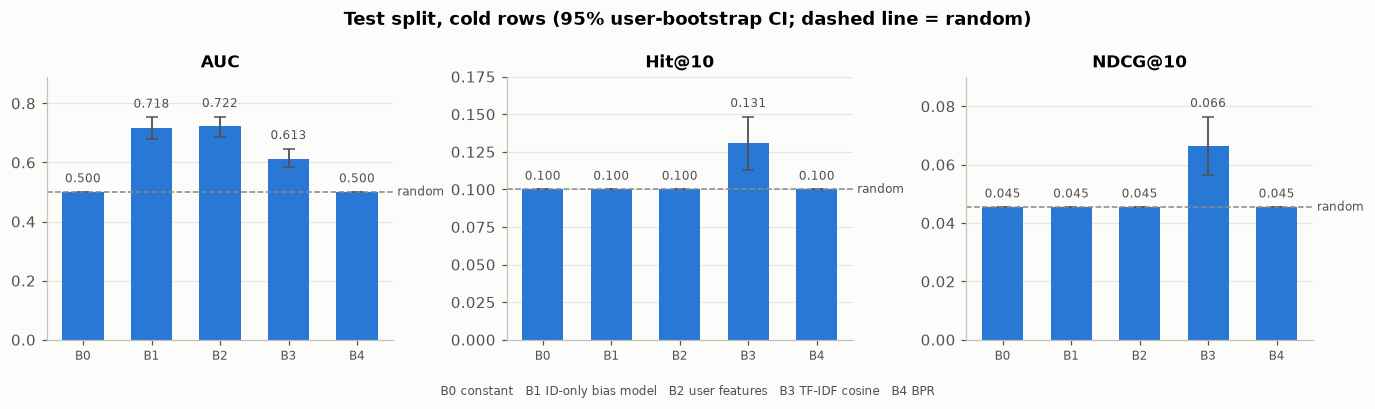

In [21]:
random_ndcg = E.ranking_metrics(cands, np.zeros(len(cands)))["NDCG@10"].mean()
P.metric_bars(test_table, ["AUC", "Hit@10", "NDCG@10"], refs={"AUC": 0.5, "Hit@10": 0.1, "NDCG@10": random_ndcg},
              suptitle="Test split, cold rows (95% user-bootstrap CI; dashed line = random)")

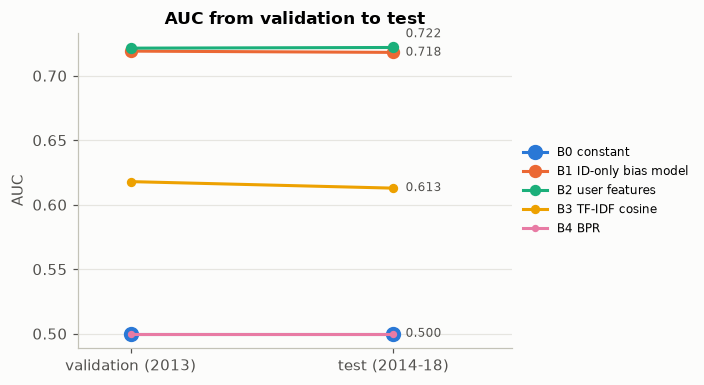

In [22]:
P.val_test_lines(table["AUC"], test_table["AUC"], "AUC")

### Takeaways


- **User information wins on AUC, recipe information wins on ranking.** B1 and B2 reach the highest AUC using only who the user is, but within one user's candidate list they give every recipe the same score, so their Hit@10 and NDCG@10 are exactly those of random guessing.
- **ID-only models cannot handle cold recipes.** BPR clearly works on warm recipes (Hit@10 0.51 vs 0.10 for random, about as good as ranking by popularity), yet on cold recipes it returns the same score for everything: AUC 0.5 and random Hit@10. B1 only survives on AUC through its user bias.
- **B3 is the only baseline that ranks recipes for a user.** Its test Hit@10 (0.131) and NDCG@10 (0.066) are above random with confidence intervals that exclude the random level. Its validation AUC is significantly below B2 (paired difference −0.103, 95% CI −0.139 to −0.070) because it ignores how generous each user is.
- The two kinds of information are complementary. **The bar for the main models (M1–M3)** is to match or beat B2 on AUC *and* B3 on Hit@10 / NDCG@10 by combining user history, recipe content, user × recipe match and author features.